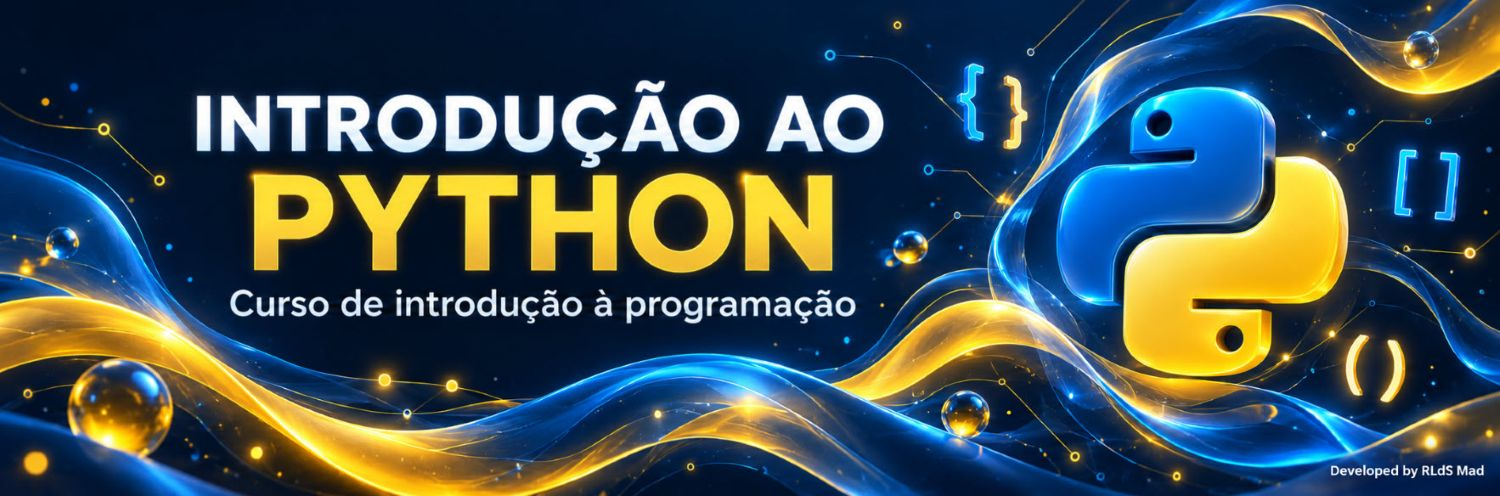

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_2_avancado/RLdS_N2_05_ScikitLearn_Aplicacoes.ipynb)


# Nível avançado · Módulo 5 – Scikit-learn: aprofundamento e aplicações
## Modelos de conjunto, confiança nas previsões e descoberta de estruturas

Este módulo dá continuidade aos módulos **Fundamentos e regressão** (módulo 3) e **Classificação e seleção de modelos** (módulo 4). Não precisa dos ficheiros anteriores: todos os conjuntos de dados e modelos são criados aqui.

**Pré-requisitos:** NumPy e Pandas; regressão e classificação; métricas; pipelines; ColumnTransformer; validação cruzada e teste independente.

**Duração sugerida:** 12–18 horas, por sessões, além do projeto autónomo.

**Objetivos:** comparar ensembles; calibrar probabilidades sem reajustar o classificador; interpretar dependências do modelo; validar por grupos e tempo; explorar clustering e PCA; guardar e recuperar uma política completa de previsão.

### Estrutura e experiências
1. Ambiente e mapa do módulo.
2. **Projeto A – Classificação:** seleção de modelos de conjunto, calibração e avaliação independente.
3. Interpretação por permutação e análise de erros.
4. **Experiência B – Grupos:** prever observações de equipamentos não vistos.
5. **Experiência C – Tempo:** prever um dia de cada vez sem usar o futuro.
6. **Projeto D – Não supervisionado:** KMeans, estabilidade e DBSCAN.
7. PCA: compressão, interpretação e utilização em pipelines.
8. Gravação, contrato de entrada, reprodução e acompanhamento.
9. Exercícios resolvidos e projeto autónomo.

As experiências usam dados **sintéticos originais** e têm objetivos e separações próprios. Não se juntam os respetivos scores numa classificação única de algoritmos.

### Como utilizar
Executa de cima para baixo com Shift + Enter em Jupyter, VS Code ou Colab. Os exercícios têm espaços de resposta facultativos e soluções executáveis no fim. As figuras ficam incorporadas nas saídas, sem imagens externas. Depois da instalação, o percurso funciona sem Internet.

Os exemplos criam ou substituem apenas ficheiros de demonstração em `sklearn03_lab`. Guarda ficheiros teus noutro local. Reinicia o kernel e executa tudo para confirmar a reprodução. No Colab, descarrega os resultados antes de terminar a sessão.

## 1. Ambiente e compatibilidade
Este módulo usa **scikit-learn 1.6+**, incluindo `FrozenEstimator` para calibrar um modelo já ajustado sem voltar a treiná-lo. Instala apenas se necessário e reinicia o kernel depois. Os tempos dependem do computador; as pesquisas foram mantidas pequenas e usam um processo para facilitar a execução local.

In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install "scikit-learn>=1.6" numpy pandas matplotlib joblib threadpoolctl

In [2]:
from pathlib import Path
from io import BytesIO
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, GroupKFold,
    TimeSeriesSplit, GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    confusion_matrix, precision_score, recall_score, f1_score, accuracy_score,
    mean_absolute_error, root_mean_squared_error, silhouette_score, adjusted_rand_score)

PASTA=Path.cwd()/"sklearn03_lab"
PASTA.mkdir(exist_ok=True)
VERSOES={p:version(p) for p in ["scikit-learn","numpy","pandas","matplotlib","joblib"]}
VERSOES["python"]=platform.python_version()
display(pd.Series(VERSOES,name="versao"))

def mostrar_figura(fig):
    b=BytesIO();fig.savefig(b,format="png",dpi=125,bbox_inches="tight")
    display(Image(data=b.getvalue()));plt.close(fig)

def prob_positiva(modelo,X):
    pos=np.flatnonzero(np.asarray(modelo.classes_)==1)
    if len(pos)!=1: raise ValueError("Classe positiva 1 não identificada.")
    return modelo.predict_proba(X)[:,int(pos[0])]

scikit-learn     1.9.1
numpy            2.5.4
pandas           3.0.6
matplotlib      3.11.2
joblib           1.6.0
python          3.12.3
Name: versao, dtype: str

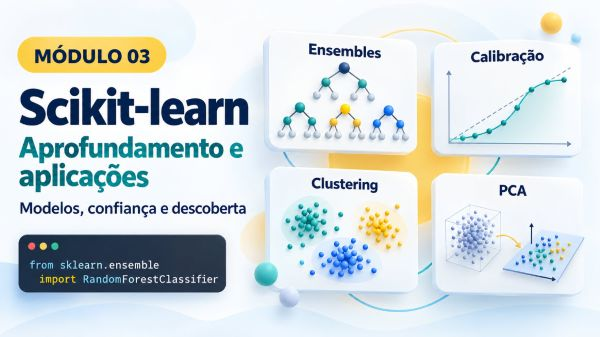

### 1.1 Mapa das escolhas
| Situação | Ferramenta / princípio |
|---|---|
| Reduzir variabilidade de árvores individuais | Random Forest: combinar árvores diversificadas |
| Aprender sequencialmente uma função mais flexível | Gradient boosting |
| Estimar probabilidades mais coerentes com frequências observadas | Calibração com dados separados |
| Ver de que entradas um modelo depende | Importância por permutação |
| Várias observações do mesmo equipamento | Separação por grupos |
| Prever o futuro com dados passados | Validação temporal e disponibilidade dos alvos |
| Explorar grupos sem rótulos | KMeans / DBSCAN |
| Reduzir dimensão linearmente | PCA |
| Reproduzir uma decisão | Preparação + estimador + classes + limiar + versões |

Mais complexidade não garante melhor desempenho. Mantemos referências simples e separamos ajuste, escolha e avaliação.

## 2. Projeto A – Sinalizar falhas numa inspeção
**Unidade:** uma peça fictícia independente, medida antes da decisão de controlo. **Alvo:** defeito observado posteriormente (`1=defeito`, `0=conforme`). As entradas são conhecidas na inspeção; não incluem o resultado final nem informação posterior.

| Campo | Significado |
|---|---|
| temperatura_C, vibracao_mm_s, horas_uso | Medições numéricas da peça/contexto |
| material | Categoria técnica fictícia A/B/C |
| linha | Linha de produção fictícia L1/L2 |
| defeito | Alvo binário |

O mecanismo gerador inclui relações não lineares e ruído. As linhas não representam medições repetidas do mesmo equipamento. A experiência por grupos, mais adiante, terá precisamente esse outro objetivo.

**Protocolo pré-definido:** 60% treino para seleção por AP CV; 20% calibração para ajustar uma transformação sigmoid; 20% teste final. A calibração será utilizada por decisão didática anterior à avaliação, mesmo que nem todas as métricas melhorem no teste. Não escolhemos depois entre versões com base no teste.

**Política fixa:** sinalizar se a probabilidade calibrada for pelo menos **0,30**. É uma política didática definida antes de observar os resultados, não um limiar otimizado nem uma recomendação operacional.

In [3]:
rng=np.random.default_rng(903)
n=1000
temp=rng.normal(65,12,n)
vib=rng.uniform(0.2,6,n)
horas=rng.uniform(100,5000,n)
material=rng.choice(["A","B","C"],n).astype(object)
linha=rng.choice(["L1","L2"],n).astype(object)
z=(-3.7+0.045*(temp-60)+0.00025*horas+0.45*(vib-2)
    +1.1*((temp>76)&(vib>3.5))+0.6*(material=="C")+0.3*(linha=="L2"))
p_geradora=1/(1+np.exp(-z))
dados=pd.DataFrame({"temperatura_C":temp,"vibracao_mm_s":vib,"horas_uso":horas,
                     "material":material,"linha":linha,"defeito":rng.binomial(1,p_geradora)})
dados.loc[rng.choice(n,30,replace=False),"temperatura_C"]=np.nan
dados.loc[rng.choice(n,20,replace=False),"material"]=np.nan
NUM=["temperatura_C","vibracao_mm_s","horas_uso"]
CAT=["material","linha"]
FEATURES=NUM+CAT
X=dados[FEATURES].copy();y=dados["defeito"].copy()
X_resto,X_teste,y_resto,y_teste=train_test_split(X,y,test_size=0.2,stratify=y,random_state=21)
X_treino,X_cal,y_treino,y_cal=train_test_split(X_resto,y_resto,test_size=0.25,stratify=y_resto,random_state=22)
for a,b in [(X_treino,X_cal),(X_treino,X_teste),(X_cal,X_teste)]:
    assert set(a.index).isdisjoint(b.index)
LIMIAR=0.30
print("Treino:",len(X_treino),"| calibração:",len(X_cal),"| teste reservado:",len(X_teste))
display(y_treino.value_counts().rename("contagem_treino"))
display(X_treino.head())

Treino: 600 | calibração: 200 | teste reservado: 200


defeito
0    497
1    103
Name: contagem_treino, dtype: int64

,temperatura_C,vibracao_mm_s,horas_uso,material,linha
965,69.358225,1.159288,3159.075009,A,L1
858,48.327071,2.793846,4587.662965,A,L1
482,51.673085,1.372874,2926.194699,A,L1
580,84.945093,2.612821,4936.040466,A,L1
803,81.326045,2.503104,4366.182485,C,L1


### Exercício 1

Descreve o papel das três partições. Verifica que treino e calibração contêm as duas classes e não partilham índices. Explica por que não devemos escolher a versão calibrada apenas depois de ver as métricas de teste.

Resolve antes de consultar a solução comentada na secção final.

In [4]:
# Exercício 1 – escreve a tua resolução aqui.


## 3. Modelos de conjunto: Random Forest e boosting
### Random Forest
Ajusta muitas árvores com diversidade de observações e/ou variáveis e agrega os seus resultados. `n_estimators` controla o número de árvores; `max_features`, `max_depth` e `min_samples_leaf` influenciam diversidade e complexidade. Não elimina sobreajuste nem resolve uma separação incorreta.

### HistGradientBoostingClassifier
Constrói um modelo de forma sequencial, melhorando uma função de perda ao longo de iterações. A versão por histogramas agrupa valores para tornar o ajuste eficiente. `learning_rate`, `max_iter`, `max_leaf_nodes` e regularização controlam a aprendizagem. Embora este estimador possa tratar NaN em condições próprias, usamos preparação explícita para manter a comparação pedagógica consistente.

Árvores não precisam geralmente de padronização. A preparação seguinte aplica escala apenas à regressão logística; os ensembles recebem valores numéricos imputados e categorias one-hot. Mantemos saída densa porque a amostra e a cardinalidade são pequenas.

In [5]:
def preparar(escalar=False):
    passos=[("imputar",SimpleImputer(strategy="median"))]
    if escalar: passos.append(("escalar",StandardScaler()))
    cat=Pipeline([("imputar",SimpleImputer(strategy="most_frequent")),
                  ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
    return ColumnTransformer([("num",Pipeline(passos),NUM),("cat",cat,CAT)])

def pipe(modelo,escalar=False):
    return Pipeline([("preparar",preparar(escalar)),("modelo",modelo)])

candidatos={
    "referencia":pipe(DummyClassifier(strategy="prior")),
    "logistica":pipe(LogisticRegression(max_iter=2000),escalar=True),
    "random_forest":pipe(RandomForestClassifier(n_estimators=80,min_samples_leaf=5,random_state=9,n_jobs=1)),
    "hist_boosting":pipe(HistGradientBoostingClassifier(max_iter=70,max_leaf_nodes=9,
                                  learning_rate=0.08,early_stopping=False,random_state=9))
}
cv=StratifiedKFold(n_splits=4,shuffle=True,random_state=23)
linhas=[]
# Limitar threads numéricas evita sobrecarga em ambientes partilhados; não altera o protocolo.
with threadpool_limits(limits=1):
    for nome,estimador in candidatos.items():
        r=cross_validate(estimador,X_treino,y_treino,cv=cv,
            scoring={"ap":"average_precision","roc":"roc_auc"},n_jobs=1,error_score="raise")
        linhas.append({"modelo":nome,"AP_cv":r["test_ap"].mean(),
                       "AP_desvio":r["test_ap"].std(ddof=1),"ROC_AUC_cv":r["test_roc"].mean()})
tabela_candidatos=pd.DataFrame(linhas).set_index("modelo").sort_values("AP_cv",ascending=False)
display(tabela_candidatos)

,AP_cv,AP_desvio,ROC_AUC_cv
modelo,,,
logistica,0.491053,0.075804,0.798443
random_forest,0.463252,0.071175,0.774355
hist_boosting,0.441470,0.116903,0.773678
referencia,0.171667,0.003333,0.500000


### 3.1 Uma pesquisa pequena com configurações declaradas

Escolhemos por AP nos mesmos folds de treino. A escala acompanha a família do modelo. O conjunto de calibração não participa na escolha.

In [6]:
grelha=[
    {"preparar":[preparar(False)],"modelo":[DummyClassifier(strategy="prior")]},
    {"preparar":[preparar(True)],"modelo":[LogisticRegression(max_iter=2000)],"modelo__C":[0.1,1.]},
    {"preparar":[preparar(False)],"modelo":[RandomForestClassifier(n_estimators=80,random_state=9,n_jobs=1)],
     "modelo__min_samples_leaf":[3,10]},
    {"preparar":[preparar(False)],"modelo":[HistGradientBoostingClassifier(max_iter=70,early_stopping=False,random_state=9)],
     "modelo__max_leaf_nodes":[5,11],"modelo__learning_rate":[0.05,0.1]}
]
pesquisa=GridSearchCV(pipe(LogisticRegression(max_iter=2000)),grelha,scoring="average_precision",
                      cv=cv,refit=True,n_jobs=1,error_score="raise")
with threadpool_limits(limits=1):pesquisa.fit(X_treino,y_treino)
modelo_base=pesquisa.best_estimator_
print("Família selecionada:",type(modelo_base.named_steps["modelo"]).__name__)
print("Melhor AP CV:",pesquisa.best_score_)
print("Parâmetros:",{k:str(v) for k,v in pesquisa.best_params_.items()})
assert modelo_base.n_features_in_==len(FEATURES)

Família selecionada: LogisticRegression
Melhor AP CV: 0.49456207114598727
Parâmetros: {'modelo': 'LogisticRegression(max_iter=2000)', 'modelo__C': '0.1', 'preparar': "ColumnTransformer(transformers=[('num',\n                                 Pipeline(steps=[('imputar',\n                                                  SimpleImputer(strategy='median')),\n                                                 ('escalar',\n                                                  StandardScaler())]),\n                                 ['temperatura_C', 'vibracao_mm_s',\n                                  'horas_uso']),\n                                ('cat',\n                                 Pipeline(steps=[('imputar',\n                                                  SimpleImputer(strategy='most_frequent')),\n                                                 ('onehot',\n                                                  OneHotEncoder(handle_unknown='ignore',\n                                            

**Interpretação:** O score vencedor foi usado para selecionar e pode ser otimista. Não é uma avaliação independente. Boosting ou Random Forest podem perder para a regressão logística: a escolha é empírica, não uma hierarquia fixa de sofisticação.

### Exercício 2

Consulta `pesquisa.cv_results_` e apresenta as três configurações com maior AP média. Identifica quantas configurações foram avaliadas. Explica por que aumentar o número de árvores não corrige fuga de informação.

Resolve antes de consultar a solução comentada na secção final.

In [7]:
# Exercício 2 – escreve a tua resolução aqui.


## 4. Calibrar probabilidades com um estimador congelado
Um modelo pode ordenar bem as observações e produzir probabilidades demasiado extremas ou conservadoras. Calibração procura alinhar probabilidades e frequências observadas em dados adequados.

Usamos `CalibratedClassifierCV(FrozenEstimator(modelo_base), method="sigmoid")`. O classificador já está ajustado no treino; o wrapper impede novo ajuste e aprende a calibração nas linhas separadas de calibração. **É nossa responsabilidade garantir que essas linhas são distintas do treino.**

Sigmoid é uma transformação paramétrica; isotonic é mais flexível e pode precisar de mais dados para evitar sobreajuste. Não vamos escolher o método observando o teste. Calibrar não garante melhoria de todas as métricas nem resolve mudanças futuras de distribuição.

In [8]:
p_cal_antes=prob_positiva(modelo_base,X_cal)
calibrado=CalibratedClassifierCV(FrozenEstimator(modelo_base),method="sigmoid")
with threadpool_limits(limits=1):calibrado.fit(X_cal,y_cal)
np.testing.assert_allclose(prob_positiva(modelo_base,X_cal),p_cal_antes)
print("O classificador de base conservou as previsões; só o calibrador foi ajustado.")
print("Classes da política calibrada:",calibrado.classes_)
assert np.array_equal(calibrado.classes_,[0,1])

O classificador de base conservou as previsões; só o calibrador foi ajustado.
Classes da política calibrada: [0 1]


### 4.1 Métricas de probabilidade e decisão
- AP e ROC-AUC medem ordenação; não demonstram calibração.
- Brier e log loss avaliam a qualidade das probabilidades, mas não isolam apenas calibração.
- Um diagrama de fiabilidade compara média prevista e frequência observada por intervalo; contagens pequenas tornam essa comparação incerta.
- O limiar fixo 0,30 transforma probabilidades em alertas. Probabilidades e decisões não são equivalentes.

Só agora abrimos o **teste reservado**. A política principal será a versão calibrada com o limiar definido. A versão não calibrada e a referência são comparações planeadas, não alternativas escolhidas após estes resultados.

In [9]:
def metricas_prob(y_real,p):
    return {"AP":average_precision_score(y_real,p),"ROC_AUC":roc_auc_score(y_real,p),
            "Brier":brier_score_loss(y_real,p),
            "log_loss":log_loss(y_real,np.column_stack([1-p,p]),labels=[0,1])}

p_teste_base=prob_positiva(modelo_base,X_teste)
p_teste_cal=prob_positiva(calibrado,X_teste)
referencia=DummyClassifier(strategy="prior").fit(X_treino,y_treino)
p_teste_ref=prob_positiva(referencia,X_teste)
metricas_finais=pd.DataFrame({"referencia":metricas_prob(y_teste,p_teste_ref),
    "modelo_base":metricas_prob(y_teste,p_teste_base),"politica_calibrada":metricas_prob(y_teste,p_teste_cal)}).T
display(metricas_finais)
prev_teste=(p_teste_cal>=LIMIAR).astype(int)
tn,fp,fn,tp=confusion_matrix(y_teste,prev_teste,labels=[0,1]).ravel()
politica_final={"limiar":LIMIAR,"precision":precision_score(y_teste,prev_teste,zero_division=0),
    "recall":recall_score(y_teste,prev_teste,zero_division=0),"F1":f1_score(y_teste,prev_teste,zero_division=0),
    "alertas":int(prev_teste.sum()),"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}
display(pd.Series(politica_final,name="teste"))
assert tn+fp+fn+tp==len(y_teste)

,AP,ROC_AUC,Brier,log_loss
referencia,0.175000,0.500000,0.144386,0.463765
modelo_base,0.523401,0.815238,0.112363,0.364084
politica_calibrada,0.523401,0.815238,0.110630,0.366399


limiar         0.300000
precision      0.512821
recall         0.571429
F1             0.540541
alertas       39.000000
TN           146.000000
FP            19.000000
FN            15.000000
TP            20.000000
Name: teste, dtype: float64

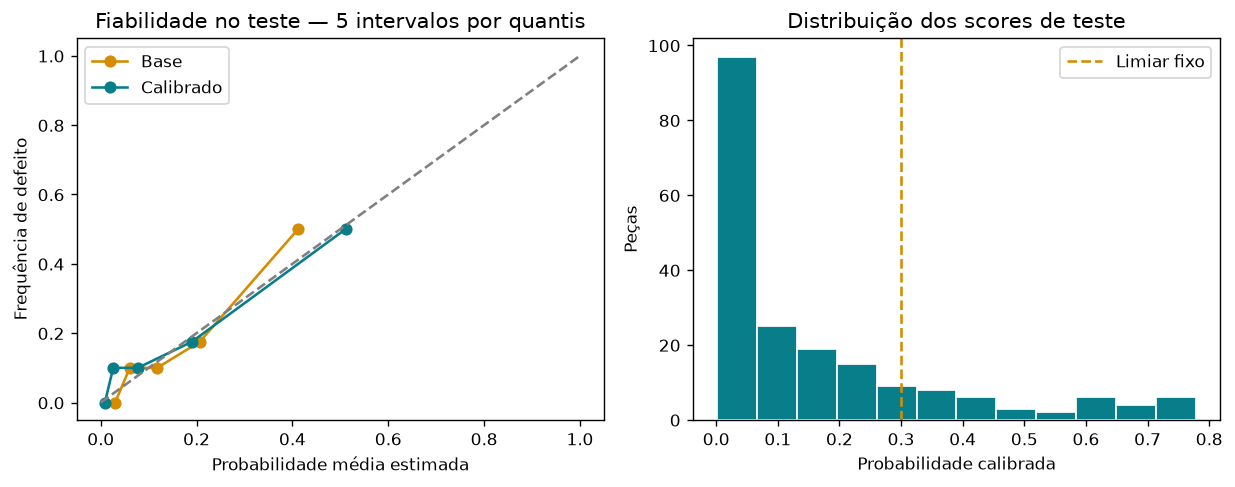

,n,p_media,observado
intervalo,,,
"(4.9999999999999914e-05, 0.0153]",40,0.008651,0.000
"(0.0153, 0.0388]",40,0.026028,0.100
"(0.0388, 0.13]",40,0.077422,0.100
"(0.13, 0.284]",40,0.189880,0.175
"(0.284, 0.779]",40,0.510929,0.500


As diferenças observadas não autorizam escolher outra calibração usando este teste.


In [10]:
fig,eixos=plt.subplots(1,2,figsize=(10,4))
for nome,p,cor in [("Base",p_teste_base,"#d58c00"),("Calibrado",p_teste_cal,"#087e8b")]:
    fracao,media=calibration_curve(y_teste,p,n_bins=5,strategy="quantile")
    eixos[0].plot(media,fracao,"o-",label=nome,color=cor)
eixos[0].plot([0,1],[0,1],"--",color="grey")
eixos[0].set(xlabel="Probabilidade média estimada",ylabel="Frequência de defeito",title="Fiabilidade no teste — 5 intervalos por quantis")
eixos[0].legend()
eixos[1].hist(p_teste_cal,bins=12,color="#087e8b",edgecolor="white")
eixos[1].axvline(LIMIAR,color="#d58c00",ls="--",label="Limiar fixo")
eixos[1].set(xlabel="Probabilidade calibrada",ylabel="Peças",title="Distribuição dos scores de teste")
eixos[1].legend();fig.tight_layout();mostrar_figura(fig)
inspecao=pd.DataFrame({"p":p_teste_cal,"y":y_teste.to_numpy()})
inspecao["intervalo"]=pd.qcut(inspecao["p"],q=5,duplicates="drop")
display(inspecao.groupby("intervalo",observed=True).agg(n=("y","size"),p_media=("p","mean"),observado=("y","mean")))
print("As diferenças observadas não autorizam escolher outra calibração usando este teste.")

### Exercício 3

Confirma que as probabilidades do classificador de base não mudaram após calibrar. Explica por que avaliar a calibração nas próprias linhas usadas para a ajustar seria otimista. Interpreta Brier e AP como medidas diferentes.

Resolve antes de consultar a solução comentada na secção final.

In [11]:
# Exercício 3 – escreve a tua resolução aqui.


## 5. Interpretação por permutação: de que depende o modelo?
A importância por permutação mede a queda de um score quando baralhamos uma entrada e mantemos as outras. Usamos a **pipeline completa** e as colunas originais do teste, para que cada categoria seja tratada como uma única variável na permutação.

Esta análise é planeada para interpretação do modelo final; não fazemos seleção de variáveis ou reajustes a partir dela. Se o fizéssemos, o teste deixaria de ser independente dessas alterações.

A importância depende do modelo, da métrica, dos dados e da correlação entre variáveis. Não é causalidade. Variáveis redundantes podem repartir ou esconder importância. Valores negativos podem ocorrer por variação amostral ou porque a perturbação melhorou o score nesta amostra.

,variavel,queda_AP_media,desvio_repeticoes
3,material,-0.001897,0.012122
4,linha,0.022242,0.019298
2,horas_uso,0.098544,0.036289
0,temperatura_C,0.108026,0.041542
1,vibracao_mm_s,0.191548,0.044621


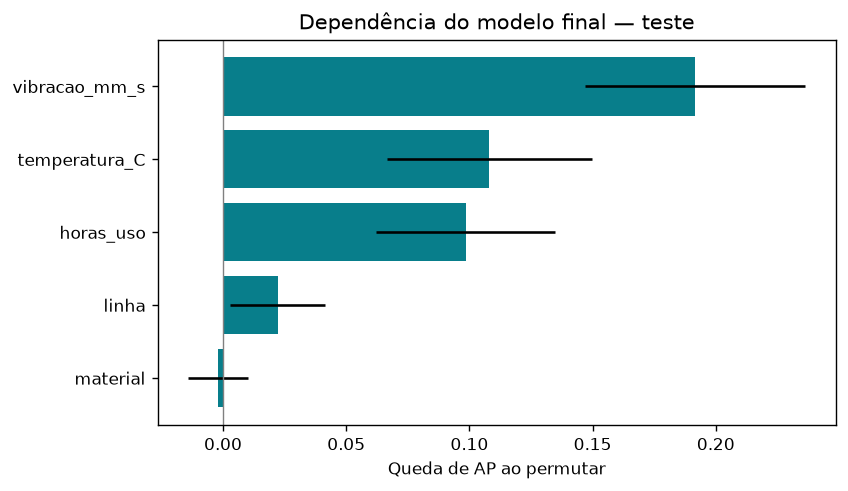

In [12]:
with threadpool_limits(limits=1):
    importancia=permutation_importance(calibrado,X_teste,y_teste,scoring="average_precision",
                                       n_repeats=8,random_state=30,n_jobs=1)
tabela_importancia=pd.DataFrame({"variavel":FEATURES,"queda_AP_media":importancia.importances_mean,
                                 "desvio_repeticoes":importancia.importances_std}).sort_values("queda_AP_media")
display(tabela_importancia)
fig,ax=plt.subplots(figsize=(7,4))
ax.barh(tabela_importancia["variavel"],tabela_importancia["queda_AP_media"],
        xerr=tabela_importancia["desvio_repeticoes"],color="#087e8b")
ax.axvline(0,color="grey",lw=0.8)
ax.set(xlabel="Queda de AP ao permutar",title="Dependência do modelo final — teste")
mostrar_figura(fig)

### 5.1 Erros por subgrupo com denominadores

Comparamos linhas de produção sem transformar o resultado numa nova escolha de modelo. Grupos com poucos positivos podem ter recalls muito variáveis. Sem desenho e dados adicionais, isto não é uma avaliação completa de equidade.

In [13]:
avaliacao=X_teste.copy()
avaliacao["observado"]=y_teste
avaliacao["p_defeito"]=p_teste_cal
avaliacao["alerta"]=prev_teste
por_linha=[]
for nome,g in avaliacao.groupby("linha"):
    por_linha.append({"linha":nome,"n":len(g),"positivos":int(g["observado"].sum()),
                     "alertas":int(g["alerta"].sum()),
                     "recall":recall_score(g["observado"],g["alerta"],zero_division=0)})
display(pd.DataFrame(por_linha))
print("Uma diferença pode refletir composição, ruído ou limitações; não identifica por si só a causa.")

,linha,n,positivos,alertas,recall
0,L1,102,15,18,0.466667
1,L2,98,20,21,0.650000


Uma diferença pode refletir composição, ruído ou limitações; não identifica por si só a causa.


### Exercício 4

Usa a tabela de permutação para identificar a variável com maior queda média de AP. Explica por que o desvio das oito permutações não é um intervalo de confiança do efeito causal e por que não deves remover variáveis usando este teste.

Resolve antes de consultar a solução comentada na secção final.

In [14]:
# Exercício 4 – escreve a tua resolução aqui.


## 6. Experiência B – Generalizar para equipamentos não vistos
Cada equipamento tem seis registos e uma assinatura numérica quase constante. O alvo inclui um efeito específico do equipamento. Se dividirmos registos aleatoriamente, observações do mesmo equipamento podem aparecer dos dois lados.

**Pergunta desta experiência:** prever para equipamentos novos. Portanto, todas as observações de um equipamento têm de ficar juntas. Não incluímos o código do equipamento como entrada; ainda assim, as assinaturas podem permitir reconhecer equipamentos.

`GroupKFold` separa grupos. Se também precisasses de preservar aproximadamente proporções em classificação, estudarias `StratifiedGroupKFold`. Separar grupos e respeitar tempo em simultâneo pode exigir um splitter personalizado.

In [15]:
rng_grupos=np.random.default_rng(100)
n_grupos=45;registos_por_grupo=6
grupo=np.repeat(np.arange(n_grupos),registos_por_grupo)
assinatura=rng_grupos.normal(size=(n_grupos,5))
efeito=rng_grupos.normal(0,8,n_grupos)
X_grupos=assinatura[grupo]+rng_grupos.normal(0,0.02,size=(len(grupo),5))
y_grupos=efeito[grupo]+rng_grupos.normal(0,0.3,len(grupo))
modelo_grupos=Pipeline([("escalar",StandardScaler()),("modelo",KNeighborsRegressor(n_neighbors=3))])
cv_aleatoria=KFold(n_splits=5,shuffle=True,random_state=2)
cv_grupos=GroupKFold(n_splits=5)
r_aleatoria=cross_validate(modelo_grupos,X_grupos,y_grupos,cv=cv_aleatoria,
                           scoring="neg_mean_absolute_error",error_score="raise")
r_grupos=cross_validate(modelo_grupos,X_grupos,y_grupos,cv=cv_grupos,groups=grupo,
                        scoring="neg_mean_absolute_error",error_score="raise")
display(pd.DataFrame({"protocolo":["registos aleatórios","equipamentos separados"],
    "MAE_medio":[-r_aleatoria["test_score"].mean(),-r_grupos["test_score"].mean()]}))
tr_gr,va_gr=next(cv_grupos.split(X_grupos,y_grupos,groups=grupo))
assert set(grupo[tr_gr]).isdisjoint(grupo[va_gr])
print("Equipamentos do primeiro treino/validação:",len(np.unique(grupo[tr_gr])),len(np.unique(grupo[va_gr])))

,protocolo,MAE_medio
0,registos aleatórios,0.457688
1,equipamentos separados,7.886126


Equipamentos do primeiro treino/validação: 36 9


A diferença mostra que os protocolos medem tarefas diferentes. Uma divisão aleatória pode fazer sentido para novas observações de equipamentos já conhecidos, desde que a ordem temporal e a disponibilidade sejam respeitadas. Não é uma comparação em que devemos simplesmente escolher o menor MAE: o objetivo define a separação correta.

### Exercício 5

Percorre os cinco folds de GroupKFold e confirma que nenhum equipamento aparece no treino e na validação do mesmo fold. Conta quantos registos de validação existem em cada fold.

Resolve antes de consultar a solução comentada na secção final.

In [16]:
# Exercício 5 – escreve a tua resolução aqui.


## 7. Experiência C – Prever um dia de cada vez
Geramos uma série diária sintética e prevemos o valor do dia usando medições anteriores e calendário. As variáveis são criadas com `shift` antes das janelas; não usamos médias centradas nem preenchimento com o futuro.

**Momento da previsão:** início do dia. O alvo de um dia só fica disponível no início do seguinte. Usaremos uma separação conservadora com um dia de `gap` para manter a disponibilidade de treino estritamente anterior ao início da validação.

**Protocolo de previsão:** um passo de cada vez, atualizando as entradas com as medições já observadas dos dias anteriores; o modelo mantém-se fixo durante cada bloco de validação. Não é uma previsão de todo o horizonte feita de uma vez. Para essa tarefa, não poderíamos usar medições reais que só surgem dentro do horizonte.

In [17]:
rng_tempo=np.random.default_rng(70)
N_TEMPO=180
serie=pd.DataFrame({"data":pd.date_range("2025-01-01",periods=N_TEMPO,freq="D")})
t=np.arange(N_TEMPO)
serie["valor"]=100+0.12*t+12*np.sin(2*np.pi*t/7)+rng_tempo.normal(0,3,N_TEMPO)
serie["lag1"]=serie["valor"].shift(1)
serie["lag7"]=serie["valor"].shift(7)
serie["media7_passado"]=serie["valor"].shift(1).rolling(7).mean()
serie["dia_sin"]=np.sin(2*np.pi*serie["data"].dt.dayofweek/7)
serie["dia_cos"]=np.cos(2*np.pi*serie["data"].dt.dayofweek/7)
serie["alvo_disponivel"]=serie["data"]+pd.Timedelta(days=1)
serie=serie.dropna().reset_index(drop=True)
COL_TEMPO=["lag1","lag7","media7_passado","dia_sin","dia_cos"]
# Últimos 21 dias reservados; um dia anterior excluído do ajuste final.
dev_tempo=serie.iloc[:-22].copy()
teste_tempo=serie.iloc[-21:].copy()
X_tempo=dev_tempo[COL_TEMPO];y_tempo=dev_tempo["valor"]
modelo_tempo=Pipeline([("escalar",StandardScaler()),("modelo",Ridge(alpha=1.0))])
cv_tempo=TimeSeriesSplit(n_splits=4,test_size=20,gap=1)
for i,(tr,va) in enumerate(cv_tempo.split(X_tempo),1):
    assert dev_tempo.iloc[tr]["data"].max()<dev_tempo.iloc[va]["data"].min()
    assert dev_tempo.iloc[tr]["alvo_disponivel"].max()<dev_tempo.iloc[va]["data"].min()
    print("Fold",i,"treino até",dev_tempo.iloc[tr]["data"].max().date(),
          "| validação desde",dev_tempo.iloc[va]["data"].min().date())
r_tempo=cross_validate(modelo_tempo,X_tempo,y_tempo,cv=cv_tempo,
                       scoring="neg_mean_absolute_error",error_score="raise")
print("MAE por fold:",-r_tempo["test_score"])

Fold 1 treino até 2025-03-18 | validação desde 2025-03-20
Fold 2 treino até 2025-04-07 | validação desde 2025-04-09
Fold 3 treino até 2025-04-27 | validação desde 2025-04-29
Fold 4 treino até 2025-05-17 | validação desde 2025-05-19
MAE por fold: [2.77888837 2.32876645 3.06685564 2.73119638]


### 7.1 Avaliação temporal reservada e referência sazonal

O modelo tem hiperparâmetros fixos nesta experiência; não os escolhemos no teste temporal. Comparamos com prever o valor da mesma posição da semana anterior (`lag7`).

MAE_Ridge_teste    2.439295
MAE_lag7_teste     3.251252
dtype: float64

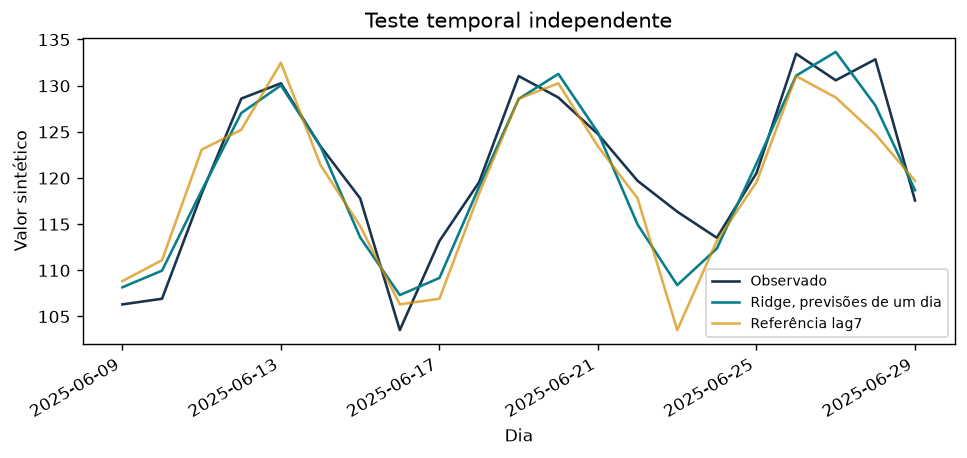

In [18]:
assert dev_tempo["alvo_disponivel"].max()<teste_tempo["data"].min()
modelo_tempo.fit(X_tempo,y_tempo)
pred_tempo=modelo_tempo.predict(teste_tempo[COL_TEMPO])
display(pd.Series({"MAE_Ridge_teste":mean_absolute_error(teste_tempo["valor"],pred_tempo),
                   "MAE_lag7_teste":mean_absolute_error(teste_tempo["valor"],teste_tempo["lag7"])}))
fig,ax=plt.subplots(figsize=(9,3.6))
ax.plot(teste_tempo["data"],teste_tempo["valor"],label="Observado",color="#18344c")
ax.plot(teste_tempo["data"],pred_tempo,label="Ridge, previsões de um dia",color="#087e8b")
ax.plot(teste_tempo["data"],teste_tempo["lag7"],label="Referência lag7",color="#d58c00",alpha=0.7)
ax.set(xlabel="Dia",ylabel="Valor sintético",title="Teste temporal independente")
ax.legend(fontsize=8);fig.autofmt_xdate();mostrar_figura(fig)

**Interpretação:** `gap` é um número de observações, não uma duração. Só equivale aqui a dias porque a série é regular e tem uma observação por dia. Um gap adequado deve refletir o horizonte, os rótulos e a latência dos dados, não um valor escolhido arbitrariamente para melhorar métricas.

### Exercício 6

Verifica manualmente uma linha: lag1 é o valor do dia anterior e media7_passado não contém o alvo do dia. Explica por que uma janela `rolling(..., center=True)` seria problemática neste cenário preditivo.

Resolve antes de consultar a solução comentada na secção final.

In [19]:
# Exercício 6 – escreve a tua resolução aqui.


## 8. Projeto D – Descobrir grupos sem rótulos
Clustering organiza observações semelhantes sem um alvo supervisionado. Os números dos clusters são etiquetas arbitrárias: cluster 0 não significa “melhor”, “normal” ou uma classe verdadeira.

Criamos quatro variáveis numéricas sintéticas com três centros, mas não entregamos as etiquetas geradoras ao algoritmo. A estrutura de referência só será usada para discussão didática, não para escolher K.

### KMeans
Procura centros e minimiza distâncias quadráticas aos centros atribuídos. Precisa de K. Funciona melhor com uma geometria compatível com grupos aproximadamente compactos; escalas e variáveis irrelevantes influenciam a solução. `n_init` controla reinicializações; fixamos explicitamente `n_init=10` e a semente.

In [20]:
centros=np.array([[0.,0.,0.,0.],[3.,2.,2.,-1.],[-3.,2.,-2.,1.]])
X_cluster,grupos_geradores=make_blobs(n_samples=300,centers=centros,cluster_std=[0.65,0.8,0.7],random_state=52)
# Escalas observadas diferentes, para tornar a preparação explícita.
X_cluster=X_cluster*np.array([1.,100.,0.1,10.])
escalador_cluster=StandardScaler().fit(X_cluster)
Z_cluster=escalador_cluster.transform(X_cluster)
resultados_k=[]
modelos_k={}
with threadpool_limits(limits=1):
    for k in range(2,7):
        km=KMeans(n_clusters=k,n_init=10,random_state=5).fit(Z_cluster)
        modelos_k[k]=km
        resultados_k.append({"k":k,"inercia":km.inertia_,"silhouette":silhouette_score(Z_cluster,km.labels_)})
tabela_k=pd.DataFrame(resultados_k)
display(tabela_k)
k_escolhido=int(tabela_k.sort_values("silhouette",ascending=False).iloc[0]["k"])
km_escolhido=modelos_k[k_escolhido]
print("K sugerido pelo critério interno nesta exploração:",k_escolhido)
print("Contagens:",np.unique(km_escolhido.labels_,return_counts=True))

,k,inercia,silhouette
0,2,640.848943,0.427141
1,3,338.554912,0.476868
2,4,289.816588,0.415930
3,5,257.301860,0.338212
4,6,233.487868,0.264072


K sugerido pelo critério interno nesta exploração: 3
Contagens: (array([0, 1, 2], dtype=int32), array([106,  95,  99]))


### 8.1 Interpretar índices internos e estabilidade
Silhouette varia entre −1 e 1 e avalia coesão/separação no espaço de distâncias escolhido; não comprova que existam segmentos úteis no mundo real. Exige entre 2 e n−1 grupos. A inércia tende a descer com K, pelo que não se escolhe automaticamente o maior K.

A análise é **exploratória no mesmo conjunto**, sem estimar desempenho de classificação fora da amostra. Num projeto operacional, valida utilidade, estabilidade em novas amostras e coerência com o domínio.

Comparamos sementes por adjusted Rand index (ARI), que é invariante à numeração dos clusters. Aqui o ARI compara duas soluções do algoritmo, não rótulos verdadeiros.

ARI entre duas sementes: 1.0


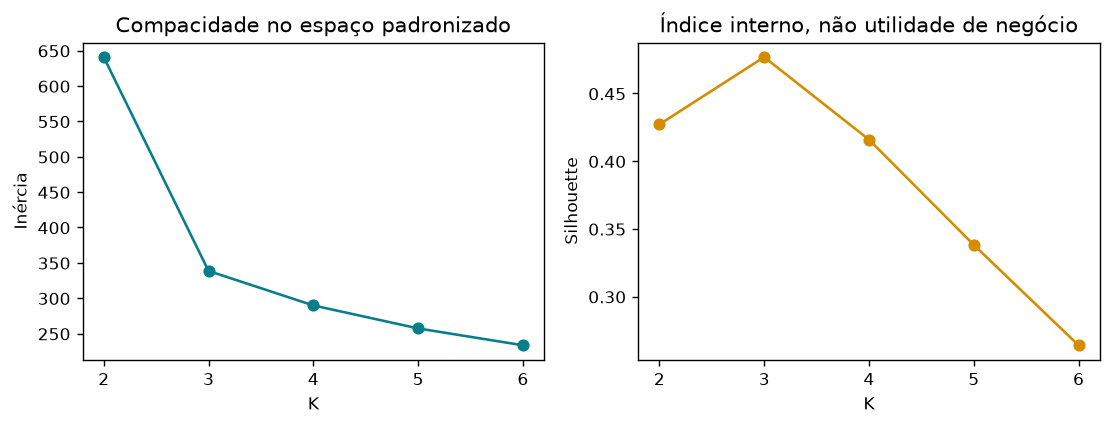

Estabilidade entre duas sementes não demonstra estabilidade entre populações ou períodos.


In [21]:
with threadpool_limits(limits=1):
    km_outra_semente=KMeans(n_clusters=k_escolhido,n_init=10,random_state=88).fit(Z_cluster)
ari_estabilidade=adjusted_rand_score(km_escolhido.labels_,km_outra_semente.labels_)
print("ARI entre duas sementes:",ari_estabilidade)
fig,eixos=plt.subplots(1,2,figsize=(9,3.5))
eixos[0].plot(tabela_k["k"],tabela_k["inercia"],"o-",color="#087e8b")
eixos[0].set(xlabel="K",ylabel="Inércia",title="Compacidade no espaço padronizado")
eixos[1].plot(tabela_k["k"],tabela_k["silhouette"],"o-",color="#d58c00")
eixos[1].set(xlabel="K",ylabel="Silhouette",title="Índice interno, não utilidade de negócio")
fig.tight_layout();mostrar_figura(fig)
print("Estabilidade entre duas sementes não demonstra estabilidade entre populações ou períodos.")

### Exercício 7

Obtém os centroides do KMeans escolhido na escala original com `inverse_transform` do escalador. Confirma a forma e descreve duas limitações de atribuir significado a esses centros.

Resolve antes de consultar a solução comentada na secção final.

In [22]:
# Exercício 7 – escreve a tua resolução aqui.


## 9. DBSCAN: grupos por densidade e ruído
DBSCAN não exige K: usa `eps` para o raio de vizinhança e `min_samples` para densidade mínima. A etiqueta **−1** representa ruído segundo a parametrização, não prova de erro ou anomalia real. É sensível à escala, à dimensão e a densidades diferentes.

Usamos um conjunto **independente** de duas formas curvas e pontos espalhados para ilustrar geometria. Não classificamos algoritmos pela aparência de um único gráfico. O estimador DBSCAN do scikit-learn não disponibiliza `predict` para novas observações; não se reutiliza simplesmente como o KMeans.

Grupos: 2 | ruído: 17 de 270
Pontos core: 246
Silhouette APENAS dos não-ruído: 0.37770005750760866


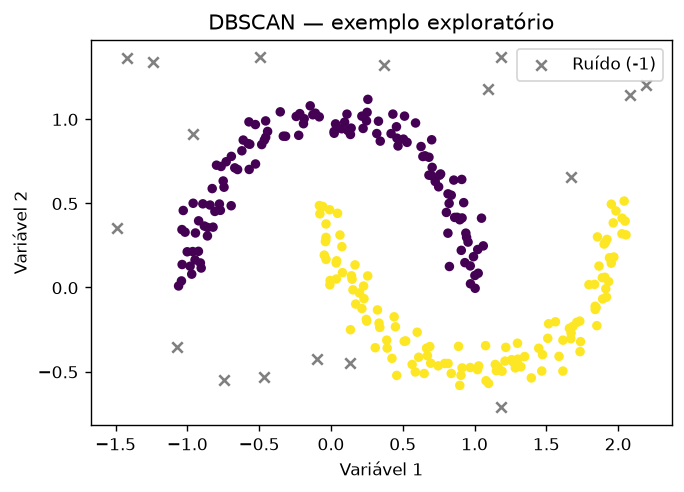

In [23]:
X_luas,_=make_moons(n_samples=250,noise=0.06,random_state=11)
rng_ruido=np.random.default_rng(12)
X_densidade=np.vstack([X_luas,rng_ruido.uniform([-1.5,-1.0],[2.5,1.5],size=(20,2))])
Z_densidade=StandardScaler().fit_transform(X_densidade)
db=DBSCAN(eps=0.25,min_samples=6).fit(Z_densidade)
rotulos_db=db.labels_
numero_grupos=len(set(rotulos_db)-{-1})
ruido=rotulos_db==-1
print("Grupos:",numero_grupos,"| ruído:",ruido.sum(),"de",len(rotulos_db))
print("Pontos core:",len(db.core_sample_indices_))
sem_ruido=~ruido
# Se reportar silhouette sem ruído, explicitar o subconjunto e verificar o domínio da métrica.
if 2<=len(np.unique(rotulos_db[sem_ruido]))<sem_ruido.sum():
    print("Silhouette APENAS dos não-ruído:",silhouette_score(Z_densidade[sem_ruido],rotulos_db[sem_ruido]))
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(X_densidade[sem_ruido,0],X_densidade[sem_ruido,1],c=rotulos_db[sem_ruido],cmap="viridis",s=20)
ax.scatter(X_densidade[ruido,0],X_densidade[ruido,1],marker="x",color="grey",label="Ruído (-1)")
ax.set(xlabel="Variável 1",ylabel="Variável 2",title="DBSCAN — exemplo exploratório");ax.legend()
mostrar_figura(fig)

### Exercício 8

Sem alterar os resultados principais, ajusta outro DBSCAN com `eps=0.18` e os mesmos dados padronizados. Conta grupos e ruído; explica por que mais ruído não significa necessariamente um algoritmo pior.

Resolve antes de consultar a solução comentada na secção final.

In [24]:
# Exercício 8 – escreve a tua resolução aqui.


## 10. PCA: reduzir dimensão sem confundir variância com previsão
PCA encontra direções ortogonais que maximizam sucessivamente a variância dos dados centrados. `PCA` centra por defeito, mas **não padroniza automaticamente cada variável**. A escala pode mudar completamente o resultado.

- `components_`: direções, uma por linha, na ordem das entradas.
- `explained_variance_ratio_`: fração da variância explicada por componente.
- `transform`: projeção nas componentes aprendidas.
- `inverse_transform`: reconstrução aproximada no espaço de entrada do PCA.

Não procura classes nem preserva necessariamente a informação mais útil para prever um alvo. Duas observações sobrepostas na projeção 2D podem estar separadas nas dimensões omitidas. O sinal das componentes pode inverter sem alterar a solução.

Forma original/projetada: (300, 4) (300, 2)
Variância explicada: [0.60940163 0.25129588]
Soma explicada: 0.8606975152863741
Erro quadrático médio de reconstrução no espaço padronizado: 0.1393024847136258


,v1,v2,v3,v4
PC1,0.601103,0.024884,0.596746,-0.530990
PC2,-0.059291,0.994425,-0.047064,-0.073409


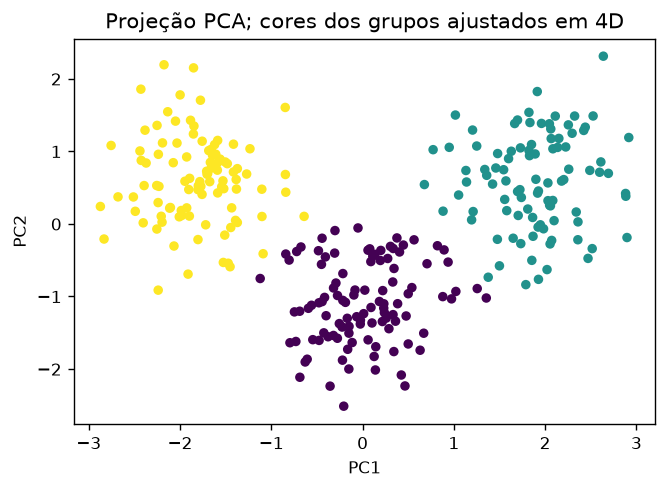

In [25]:
pca_vis=PCA(n_components=2,svd_solver="full").fit(Z_cluster)
projecao=pca_vis.transform(Z_cluster)
reconstrucao=pca_vis.inverse_transform(projecao)
print("Forma original/projetada:",Z_cluster.shape,projecao.shape)
print("Variância explicada:",pca_vis.explained_variance_ratio_)
print("Soma explicada:",pca_vis.explained_variance_ratio_.sum())
print("Erro quadrático médio de reconstrução no espaço padronizado:",np.mean((Z_cluster-reconstrucao)**2))
display(pd.DataFrame(pca_vis.components_,columns=["v1","v2","v3","v4"],index=["PC1","PC2"]))
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(projecao[:,0],projecao[:,1],c=km_escolhido.labels_,cmap="viridis",s=20)
ax.set(xlabel="PC1",ylabel="PC2",title="Projeção PCA; cores dos grupos ajustados em 4D")
mostrar_figura(fig)

### 10.1 PCA como transformação dentro de uma pipeline

Se PCA for parte de um modelo supervisionado, tem de ser ajustado só no treino de cada fold. Este é um estudo adicional apenas no treino do Projeto A e não muda a política final já avaliada.

In [26]:
modelo_pca=Pipeline([("preparar",preparar(True)),
    ("pca",PCA(n_components=0.95,svd_solver="full")),
    ("modelo",LogisticRegression(max_iter=2000))])
with threadpool_limits(limits=1):
    r_pca=cross_validate(modelo_pca,X_treino,y_treino,cv=cv,scoring="average_precision",error_score="raise")
print("AP CV com PCA a 95% da variância:",r_pca["test_score"].mean())
print("AP CV da referência logística sem PCA:",tabela_candidatos.loc["logistica","AP_cv"])
modelo_pca.fit(X_treino,y_treino)
print("Dimensões conservadas no ajuste ao treino:",modelo_pca.named_steps["pca"].n_components_)

AP CV com PCA a 95% da variância: 0.49119888101695164
AP CV da referência logística sem PCA: 0.49105319337126396
Dimensões conservadas no ajuste ao treino: 6


**Interpretação:** Conservar 95% da variância não garante conservar 95% da informação relevante para classificação. A comparação serve para interpretação e não é usada para alterar a seleção principal após observar o teste.

### Exercício 9

Reconstrói os dados de clustering com quatro componentes em vez de duas e compara os erros de reconstrução no espaço padronizado. Explica por que erro de reconstrução quase zero não demonstra uma boa redução de dimensão.

Resolve antes de consultar a solução comentada na secção final.

In [27]:
# Exercício 9 – escreve a tua resolução aqui.


## 11. Guardar e recuperar a política completa
O ficheiro guardado deve conter o estimador calibrado que encapsula a pipeline aprendida, o limiar e a semântica das classes. As versões e o contrato de entrada ficam também em JSON legível.

Usamos `joblib` apenas para um artefacto que **acabámos de criar neste laboratório**. Não carregues ficheiros pickle/joblib de origem não confiável: a desserialização pode executar código. A compatibilidade entre versões de scikit-learn não é garantida; regista o ambiente e volta a validar numa mudança de versões.

O exemplo grava localmente e não publica nem disponibiliza um serviço. A interpretação e os resultados de teste não modificam o modelo serializado.

In [28]:
ARTEFACTO=PASTA/"politica_defeitos.joblib"
CONTRATO={"colunas":FEATURES,"numericas":NUM,"categoricas":CAT,
          "categorias_treino":{c:sorted(X_treino[c].dropna().unique().tolist()) for c in CAT},
          "ausencias":"NaN permitido e tratado pela pipeline; infinitos rejeitados",
          "unidades":{"temperatura_C":"°C","vibracao_mm_s":"mm/s","horas_uso":"horas"}}
pacote={"estimador":calibrado,"limiar":LIMIAR,"classe_positiva":1,
        "significado_positivo":"Defeito","classes":calibrado.classes_.tolist(),
        "features":FEATURES,"contrato":CONTRATO,"versoes":VERSOES}
joblib.dump(pacote,ARTEFACTO,compress=3)
recuperado=joblib.load(ARTEFACTO)  # Só o ficheiro criado acima.
p_recuperado=prob_positiva(recuperado["estimador"],X_teste)
np.testing.assert_allclose(p_recuperado,p_teste_cal,atol=1e-12)
assert np.array_equal((p_recuperado>=recuperado["limiar"]).astype(int),prev_teste)
print("Probabilidades e decisões preservadas após recuperação.")
print("Tamanho do artefacto:",ARTEFACTO.stat().st_size,"bytes")

Probabilidades e decisões preservadas após recuperação.
Tamanho do artefacto: 2431 bytes


### 11.1 Contrato de entrada e categorias novas

As transformações não dispensam um contrato. Validamos estrutura, tipos numéricos e infinitos. NaN é permitido segundo a política de imputação. Valores categóricos novos são tecnicamente aceites pelo codificador, mas são reportados para revisão.

In [29]:
def validar_entrada(df,contrato):
    if df.columns.tolist()!=contrato["colunas"]:
        raise ValueError("Colunas ou ordem diferentes do contrato.")
    if not all(pd.api.types.is_numeric_dtype(df[c]) for c in contrato["numericas"]):
        raise ValueError("Tipos numéricos esperados.")
    if np.isinf(df[contrato["numericas"]].to_numpy(dtype=float)).any():
        raise ValueError("Valores infinitos não aceites.")
    for c in contrato["categoricas"]:
        if not df[c].dropna().map(lambda v:isinstance(v,str)).all():
            raise ValueError(f"Texto esperado em {c}.")
    desconhecidas={c:sorted(set(df[c].dropna())-set(contrato["categorias_treino"][c]))
                   for c in contrato["categoricas"]}
    return desconhecidas

novas=pd.DataFrame({"temperatura_C":[62.,85.],"vibracao_mm_s":[1.2,5.5],"horas_uso":[800.,4200.],
                    "material":["A","D"],"linha":["L1","L2"]})
novidades=validar_entrada(novas,recuperado["contrato"])
p_novas=prob_positiva(recuperado["estimador"],novas)
saida_novas=novas.assign(p_defeito=p_novas,alerta=(p_novas>=recuperado["limiar"]).astype(int))
display(saida_novas)
print("Categorias não vistas:",novidades)
print("O contrato didático não inclui todos os limites físicos: teriam de ser acordados com a origem.")

,temperatura_C,vibracao_mm_s,horas_uso,material,linha,p_defeito,alerta
0,62.0,1.2,800.0,A,L1,0.005317,0
1,85.0,5.5,4200.0,D,L2,0.860574,1


Categorias não vistas: {'material': ['D'], 'linha': []}
O contrato didático não inclui todos os limites físicos: teriam de ser acordados com a origem.


### Exercício 10

Recupera apenas o artefacto criado pelo notebook e verifica que uma linha nova produz a mesma probabilidade no modelo em memória e no recuperado. Confirma também a preservação do limiar e da ordem das classes.

Resolve antes de consultar a solução comentada na secção final.

In [30]:
# Exercício 10 – escreve a tua resolução aqui.


## 12. Acompanhamento após a entrega
Desempenho numa avaliação não garante desempenho futuro. Um processo real deve acompanhar:

- **Qualidade das entradas:** ausências, categorias novas, tipos, unidades e domínios.
- **Distribuições:** alterações nas medições e nos scores; uma mudança não prova por si só perda de desempenho.
- **Resultados com rótulos disponíveis:** métricas por período e subgrupo, prevalência e latência dos rótulos.
- **Decisões e operação:** volume de alertas, capacidade de resposta e efeitos das intervenções.
- **Versões:** dados, preparação, estimador, calibração, limiar e ambiente.

Uma deriva nos scores pode resultar de mudança das entradas, do modelo ou da população. Sem os alvos futuros não consegues medir diretamente accuracy, AP ou calibração dessa população.

In [31]:
lote_simulado=X_teste.head(40).copy()
lote_simulado["vibracao_mm_s"]=lote_simulado["vibracao_mm_s"]+1.5
lote_simulado.loc[lote_simulado.index[:5],"material"]="D"
alertas_contrato=validar_entrada(lote_simulado,CONTRATO)
p_lote=prob_positiva(calibrado,lote_simulado)
display(pd.DataFrame({"ausencias_treino":X_treino.isna().mean(),
                      "ausencias_lote":lote_simulado.isna().mean()}))
print("Categorias novas:",alertas_contrato)
print("Score médio no lote simulado:",p_lote.mean())
print("Taxa de alertas no lote:",(p_lote>=LIMIAR).mean())
print("Sem rótulos novos, não calculamos métricas de desempenho deste lote.")

,ausencias_treino,ausencias_lote
temperatura_C,0.030000,0.025
vibracao_mm_s,0.000000,0.000
horas_uso,0.000000,0.000
material,0.021667,0.050
linha,0.000000,0.000


Categorias novas: {'material': ['D'], 'linha': []}
Score médio no lote simulado: 0.31904667996045327
Taxa de alertas no lote: 0.475
Sem rótulos novos, não calculamos métricas de desempenho deste lote.


### Exercício 11

Cria uma entrada com uma coluna em falta e outra com infinito. Confirma que o contrato rejeita as duas, capturando ValueError. Explica por que o aumento de scores num lote não prova melhoria da deteção.

Resolve antes de consultar a solução comentada na secção final.

In [32]:
# Exercício 11 – escreve a tua resolução aqui.


## 13. Projeto integrado de entrega e metadados
O Projeto A reúne seleção no treino, calibração separada, avaliação independente, interpretação planeada e gravação da política. As experiências B, C e D ilustram tarefas diferentes e têm resumos separados.

In [33]:
def sha256(caminho):
    h=hashlib.sha256()
    with open(caminho,"rb") as f:
        for bloco in iter(lambda:f.read(1024*1024),b""):h.update(bloco)
    return h.hexdigest()

metadados={"origem":"Dados sintéticos originais; Projeto A semente 903","versoes":VERSOES,
    "contrato":CONTRATO,"particoes":{"treino":len(X_treino),"calibracao":len(X_cal),"teste":len(X_teste)},
    "escolha_modelo":"Maior AP CV estratificada no treino",
    "modelo_base":type(modelo_base.named_steps["modelo"]).__name__,
    "calibracao":"Sigmoid sobre FrozenEstimator; apenas conjunto de calibração",
    "politica":politica_final,"limiar_predefinido":True,
    "metricas_teste":metricas_finais.to_dict(orient="index"),
    "artefacto_sha256":sha256(ARTEFACTO),
    "limitacoes":["Dados sintéticos","Sem validação externa","Limiar didático fixo",
                  "Sem análise causal","Sem serviço publicado"]}
(PASTA/"metadados.json").write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding="utf-8")
metricas_finais.to_csv(PASTA/"metricas_teste.csv",sep=";",decimal=",",index_label="versao",encoding="utf-8-sig")
avaliacao.to_csv(PASTA/"previsoes_teste.csv",sep=";",decimal=",",index=False,encoding="utf-8-sig")
tabela_importancia.to_csv(PASTA/"permutacao.csv",sep=";",decimal=",",index=False,encoding="utf-8-sig")
saida_novas.to_csv(PASTA/"novas_pecas.csv",sep=";",decimal=",",index=False,encoding="utf-8-sig")
relatorio=f"""# Projeto A — classificação e confiança nas previsões

Dados sintéticos. Alvo: defeito (classe 1).
Modelo selecionado: {metadados['modelo_base']}.
Calibração sigmoid em conjunto separado; limiar definido previamente: {LIMIAR}.
AP no teste da política calibrada: {metricas_finais.loc['politica_calibrada','AP']:.3f}.
Brier no teste: {metricas_finais.loc['politica_calibrada','Brier']:.3f}.
Alertas: {politica_final['alertas']} de {len(X_teste)} peças.
Limitações: dados artificiais, amostra pequena para calibração, ausência de validação externa.
A análise por permutação é interpretativa e não foi usada para reajustar o modelo.
O ficheiro joblib é local e não representa um serviço operacional.
"""
(PASTA/"relatorio.md").write_text(relatorio,encoding="utf-8")
print(relatorio)
assert sha256(ARTEFACTO)==metadados["artefacto_sha256"]
print("Resultados:",sorted(p.name for p in PASTA.iterdir()))

# Projeto A — classificação e confiança nas previsões

Dados sintéticos. Alvo: defeito (classe 1).
Modelo selecionado: LogisticRegression.
Calibração sigmoid em conjunto separado; limiar definido previamente: 0.3.
AP no teste da política calibrada: 0.523.
Brier no teste: 0.111.
Alertas: 39 de 200 peças.
Limitações: dados artificiais, amostra pequena para calibração, ausência de validação externa.
A análise por permutação é interpretativa e não foi usada para reajustar o modelo.
O ficheiro joblib é local e não representa um serviço operacional.

Resultados: ['metadados.json', 'metricas_teste.csv', 'novas_pecas.csv', 'permutacao.csv', 'politica_defeitos.joblib', 'previsoes_teste.csv', 'relatorio.md']


### Exercício 12

Escreve um resumo comparando o que se aprende nos quatro cenários: classificação independente, equipamentos novos, previsão temporal e clustering. Identifica qual separação seria adequada ao teu próprio projeto e justifica-a antes de escolher o algoritmo.

Resolve antes de consultar a solução comentada na secção final.

In [34]:
# Exercício 12 – escreve a tua resolução aqui.


## 14. Soluções comentadas
As soluções não dependem de preencher as tentativas. Não alteram a política do Projeto A nem fazem nova seleção no teste.

### Exercícios 1–3 – Separação, seleção e calibração

In [35]:
# 1 – Treino seleciona; calibração ajusta o mapa de probabilidades; teste avalia.
assert set(y_treino.unique())=={0,1} and set(y_cal.unique())=={0,1}
assert set(X_treino.index).isdisjoint(X_cal.index)
print("Partições distintas verificadas.")
# Escolher a versão depois de ver o teste utilizaria o teste para seleção.

# 2 – Ranking da pesquisa; não escolher pelo erro de ajuste.
ex2=pd.DataFrame(pesquisa.cv_results_)
ex2_rank=pd.DataFrame({"configuracao":ex2["params"].map(str),"AP_cv":ex2["mean_test_score"]})
display(ex2_rank.sort_values("AP_cv",ascending=False).head(3))
print("Configurações:",len(ex2_rank))
# Mais árvores não corrigem entradas com informação futura nem grupos misturados.

# 3 – A calibração não treina novamente o estimador congelado.
np.testing.assert_allclose(prob_positiva(modelo_base,X_cal),p_cal_antes,atol=1e-12)
print("Classificador de base preservado.")
# Avaliar o calibrador nas linhas usadas no seu ajuste pode recompensar adaptação a essas linhas.
# AP avalia ordenação; Brier usa diferenças entre probabilidades e eventos observados.

Partições distintas verificadas.


,configuracao,AP_cv
1,"{'modelo': LogisticRegression(max_iter=2000), ...",0.494562
2,"{'modelo': LogisticRegression(max_iter=2000), ...",0.491053
4,{'modelo': RandomForestClassifier(n_estimators...,0.487076


Configurações: 9


Classificador de base preservado.


### Exercícios 4–6 – Interpretação e desenho de validação

In [36]:
# 4 – A importância depende da métrica e do modelo; não é um efeito de intervenção.
ex4=tabela_importancia.sort_values("queda_AP_media",ascending=False).iloc[0]
print("Maior queda média:",ex4["variavel"],ex4["queda_AP_media"])
# O desvio de permutações mede variação do baralhamento, não incerteza causal nem populacional.

# 5 – Cada equipamento fica integralmente de um lado do fold.
for i,(tr,va) in enumerate(cv_grupos.split(X_grupos,y_grupos,groups=grupo),1):
    assert set(grupo[tr]).isdisjoint(grupo[va])
    print("Fold",i,"registos de validação:",len(va))

# 6 – Verificação numa linha interior com sete dias anteriores disponíveis.
i=12
assert serie.loc[i,"data"]-serie.loc[i-1,"data"]==pd.Timedelta(days=1)
np.testing.assert_allclose(serie.loc[i,"lag1"],serie.loc[i-1,"valor"])
np.testing.assert_allclose(serie.loc[i,"media7_passado"],serie.loc[i-7:i-1,"valor"].mean())
print("Lags e janela anterior verificados.")
# center=True incluiria medições posteriores ao momento da previsão.

Maior queda média: vibracao_mm_s 0.19154834233226797
Fold 1 registos de validação: 54
Fold 2 registos de validação: 54
Fold 3 registos de validação: 54
Fold 4 registos de validação: 54
Fold 5 registos de validação: 54
Lags e janela anterior verificados.


### Exercícios 7–9 – Clustering e PCA

In [37]:
# 7 – Os centros são médias no espaço escolhido e não segmentos com significado automático.
ex7_centros=escalador_cluster.inverse_transform(km_escolhido.cluster_centers_)
print("Centros na escala original:\n",ex7_centros)
assert ex7_centros.shape==(k_escolhido,4)
# Limites: geometria/escalas escolhidas e ausência de validação de utilidade no domínio.

# 8 – Aumentar ruído pode refletir maior exigência de densidade, não um resultado pior por definição.
ex8=DBSCAN(eps=0.18,min_samples=6).fit(Z_densidade)
print("Novo eps: grupos",len(set(ex8.labels_)-{-1}),"ruído",np.count_nonzero(ex8.labels_==-1))

# 9 – Conservar as quatro dimensões elimina praticamente o erro, mas não comprime.
ex9_pca=PCA(n_components=4,svd_solver="full").fit(Z_cluster)
ex9_recon=ex9_pca.inverse_transform(ex9_pca.transform(Z_cluster))
ex9_erro=np.mean((Z_cluster-ex9_recon)**2)
print("Erro com 2 componentes:",np.mean((Z_cluster-reconstrucao)**2))
print("Erro com 4 componentes:",ex9_erro)
np.testing.assert_allclose(ex9_recon,Z_cluster,atol=1e-12)

Centros na escala original:
 [[ 1.62243798e-01  8.18657378e-01  1.19204302e-02  6.15377138e-01]
 [ 2.99203511e+00  2.00888793e+02  1.98919294e-01 -9.77576780e+00]
 [-2.96735851e+00  1.89002429e+02 -2.03575673e-01  8.18699146e+00]]


Novo eps: grupos 8 ruído 20
Erro com 2 componentes: 0.1393024847136258
Erro com 4 componentes: 6.5989433490798715e-31


### Exercícios 10–12 – Reprodução, contratos e síntese

In [38]:
# 10 – Apenas o artefacto gerado localmente neste notebook.
ex10=joblib.load(ARTEFACTO)
np.testing.assert_allclose(prob_positiva(ex10["estimador"],novas.head(1)),
                           prob_positiva(calibrado,novas.head(1)),atol=1e-12)
assert ex10["limiar"]==LIMIAR and ex10["classes"]==calibrado.classes_.tolist()
print("Reprodução preservada.")

# 11 – Falhas explícitas e capturadas.
for ex11 in [novas.drop(columns="material"),novas.assign(horas_uso=np.inf)]:
    try:validar_entrada(ex11,CONTRATO)
    except ValueError as erro:print("Rejeição esperada:",erro)
    else:raise AssertionError("Contrato deveria rejeitar a entrada.")
# Mais scores altos num lote não demonstram melhoria: faltam os rótulos para avaliar erros.

# 12 – Síntese dos objetivos, não um ranking global de algoritmos.
display(pd.DataFrame({"cenario":["Peças independentes","Equipamentos novos","Um dia de cada vez","Clustering"],
    "validacao":["Treino / calibração / teste","GroupKFold","TimeSeriesSplit + teste futuro","Exploração e estabilidade"],
    "pergunta":["Que score e decisão generalizam?","Generaliza a grupos não vistos?",
                "Prevê usando só informação disponível?","Que estrutura emerge na geometria escolhida?"]}))

Reprodução preservada.
Rejeição esperada: Colunas ou ordem diferentes do contrato.
Rejeição esperada: Valores infinitos não aceites.


,cenario,validacao,pergunta
0,Peças independentes,Treino / calibração / teste,Que score e decisão generalizam?
1,Equipamentos novos,GroupKFold,Generaliza a grupos não vistos?
2,Um dia de cada vez,TimeSeriesSplit + teste futuro,Prevê usando só informação disponível?
3,Clustering,Exploração e estabilidade,Que estrutura emerge na geometria escolhida?


## 15. Verificações finais e projeto autónomo
As verificações abaixo confirmam consistência, não uma promessa de desempenho. Não impomos uma AP arbitrária como teste de correção.

In [39]:
assert np.isfinite(p_teste_cal).all() and np.all((p_teste_cal>=0)&(p_teste_cal<=1))
assert np.array_equal(prev_teste,(p_teste_cal>=LIMIAR).astype(int))
np.testing.assert_allclose(calibrado.predict_proba(novas).sum(axis=1),1.,atol=1e-12)
for tr,va in cv_grupos.split(X_grupos,y_grupos,groups=grupo):
    assert set(grupo[tr]).isdisjoint(grupo[va])
for tr,va in cv_tempo.split(X_tempo):
    assert dev_tempo.iloc[tr]["alvo_disponivel"].max()<dev_tempo.iloc[va]["data"].min()
assert np.isfinite(projecao).all() and projecao.shape==(len(X_cluster),2)
print("Política, grupos, disponibilidade temporal e projeções verificados.")

Política, grupos, disponibilidade temporal e projeções verificados.


### Projeto autónomo
Escolhe **um** objetivo principal, sem juntar tarefas incompatíveis só para usar mais algoritmos.

1. Define a unidade de observação, o momento da previsão ou o objetivo exploratório.
2. Justifica uma separação independente, por grupos ou por tempo, quando há previsão.
3. Documenta entradas, disponibilidade, rótulos e ausências.
4. Compara uma referência e duas alternativas justificadas.
5. Aprende todas as transformações dentro do protocolo de validação.
6. Se usares probabilidades, define se precisas de calibração e como a avaliarás.
7. Se usares decisões, documenta limiar, custos e capacidade operacional.
8. Interpreta sem confundir dependência do modelo com causalidade.
9. Guarda o processo completo e confirma a reprodução.
10. Reporta limitações e o que terias de acompanhar após a entrega.

**Autoavaliação:** 0–2 pontos por item — ausente; parcialmente demonstrado; demonstrado e explicado. Total: 20 pontos. Para clustering, substitui a separação supervisionada e calibração por análise de estabilidade, geometria e utilidade.

### Consulta rápida
| Tema | API |
|---|---|
| Floresta de classificação / regressão | `RandomForestClassifier` / `RandomForestRegressor` |
| Boosting por histogramas | `HistGradientBoostingClassifier` / `HistGradientBoostingRegressor` |
| Calibrar sem reajustar um estimador já treinado | `CalibratedClassifierCV(FrozenEstimator(...))` |
| Interpretar dependências | `permutation_importance` |
| Separar equipamentos/pessoas | `GroupKFold` / `StratifiedGroupKFold` |
| Respeitar sequência temporal | `TimeSeriesSplit` |
| Agrupamentos por centros | `KMeans` |
| Densidade e ruído | `DBSCAN` |
| Redução linear | `PCA` |
| Guardar/recuperar artefacto próprio | `joblib.dump` / `joblib.load` |

### Limites do módulo
Não implementamos uma aplicação em produção, uma prova causal, uma avaliação completa de equidade, um sistema de acompanhamento automático nem uma pesquisa exaustiva de algoritmos. As experiências são pequenas e sintéticas para permitir execução e interpretação. Dados reais exigem rever domínios, escala, dependências e custos.

### Referências oficiais
- [Ensembles](https://scikit-learn.org/stable/modules/ensemble.html)
- [Calibração de probabilidades](https://scikit-learn.org/stable/modules/calibration.html)
- [FrozenEstimator](https://scikit-learn.org/stable/modules/generated/sklearn.frozen.FrozenEstimator.html)
- [Importância por permutação](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [Validação cruzada, grupos e tempo](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Clustering](https://scikit-learn.org/stable/modules/clustering.html)
- [PCA e decomposições](https://scikit-learn.org/stable/modules/decomposition.html)
- [Gravação e compatibilidade de modelos](https://scikit-learn.org/stable/model_persistence.html)

Os exemplos e dados são originais; a documentação serve para aprofundamento e confirmação das APIs.